In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:.3f}".format)

**Load TimeLag_PolicyAnnotated dataset**

In [2]:
lagged_liheap = pd.read_csv("TimeLag_PolicyAnnotated.csv")
Calfresh = pd.read_csv("CalFresh_cleaned.csv").rename(columns={"Month Year": "Month_Year"})
FoodBank = pd.read_csv("FoodBank_cleaned.csv").rename(columns={"Month Year": "Month_Year"})

**Develop the time lagged dataset with policy annotations**

In [3]:
CalFresh_Merged = (
    Calfresh.groupby(["Zip Code", "Month_Year"], as_index=False)["Calfresh Dollars"].sum()
    .rename(columns={"Calfresh Dollars": "CalFresh_Total_Dollars"})
)

FoodBank_Merged = (
    FoodBank.groupby(["Zip Code", "Month_Year"], as_index=False)["Pounds_Distributed"].sum()
    .rename(columns={"Pounds_Distributed": "FoodBank_Pounds_of_Food_Distributed"})
)

In [4]:
fb = "FoodBank_Pounds_of_Food_Distributed"
FoodBank_Merged.loc[FoodBank_Merged[fb] == 0, fb] = np.nan

In [5]:
df = (lagged_liheap
      .merge(CalFresh_Merged, on=["Zip Code", "Month_Year"], how="left", validate="one_to_one")
      .merge(FoodBank_Merged, on=["Zip Code", "Month_Year"], how="left", validate="one_to_one")
      .rename(columns={"Enrollment_Count": "LIHEAP_Enrollment_Count"})
)

assert len(df) == len(lagged_liheap)

print(df.shape)

(852, 38)


In [6]:
df[["Zip Code", "Month_Year", "LIHEAP_Enrollment_Count", "LIHEAP_lag1", "LIHEAP_lag2", "LIHEAP_lag3",
    "CalFresh_Total_Dollars", fb]].head()

,Zip Code,Month_Year,LIHEAP_Enrollment_Count,LIHEAP_lag1,LIHEAP_lag2,LIHEAP_lag3,CalFresh_Total_Dollars,FoodBank_Pounds_of_Food_Distributed
0,91901,2023-03,2.000,1.000,NaN,NaN,355789.000,51489.000
1,91901,2023-04,1.000,2.000,1.000,NaN,230000.000,26145.000
2,91901,2023-05,2.000,1.000,2.000,1.000,230786.000,27788.000
3,91901,2023-06,2.000,2.000,1.000,2.000,219267.000,17225.000
4,91901,2023-07,1.000,2.000,2.000,1.000,207889.590,20383.000


**Set up the lags and outcomes**

In [7]:
LAGS = [0, 1, 2, 3]

LIHEAP_COLS = {
    0: "LIHEAP_Enrollment_Count",
    1: "LIHEAP_lag1",
    2: "LIHEAP_lag2",
    3: "LIHEAP_lag3"
}

OUTCOMES = {"CalFresh_Total_Dollars": "CalFresh",
           "FoodBank_Pounds_of_Food_Distributed": "Food bank"}

ALPHA = 0.05

**Step 3: Correlation function with p-values and 95% confidence intervals**

In [8]:
def spearman_ci(rho, n, conf=0.95):
    """Fisher z interval for Spearman's rho (Bonett & Wright, 2000)."""
    z = np.arctanh(rho)
    se = np.sqrt((1 + rho**2 / 2) / (n - 3))
    zc = stats.norm.ppf(1 - (1 - conf) / 2)
    return np.tanh(z - zc * se), np.tanh(z + zc * se)

def correlate(x, y):
    n = len(x)
    p = stats.pearsonr(x, y)
    p_lo, p_hi = p.confidence_interval(confidence_level=1 - ALPHA)
    s =stats.spearmanr(x, y)
    s_lo, s_hi = spearman_ci(s.statistic, n, 1 - ALPHA)
    return dict(n=n,
               Pearson_r=p.statistic, Pearson_p=p.pvalue, Pearson_CI_low=p_lo, Pearson_CI_high=p_hi,
               Spearman_rho=s.statistic, Spearman_p=s.pvalue, Spearman_CI_low=s_lo, Spearman_CI_high=s_hi)

**Step 4: LIHEAP vs CalFresh and FoodBank at each lag**

In [9]:
rows = []
for out, label in OUTCOMES.items():
    for k in LAGS:
        x = LIHEAP_COLS[k]
        sub = df[[x, out]].dropna()
        row = dict(Outcome=label, Lag=k)
        if len(sub) >= 10 and sub[x].nunique() > 1:
            row.update(correlate(sub[x], sub[out]))
        else:
            row.update(n=len(sub))
        rows.append(row)

results = pd.DataFrame(rows)
results

,Outcome,Lag,n,Pearson_r,Pearson_p,Pearson_CI_low,Pearson_CI_high,Spearman_rho,Spearman_p,Spearman_CI_low,Spearman_CI_high
0,CalFresh,0,453,0.566,0.000,0.500,0.625,0.644,0.000,0.581,0.700
1,CalFresh,1,577,0.567,0.000,0.508,0.620,0.681,0.000,0.629,0.727
2,CalFresh,2,578,0.549,0.000,0.489,0.603,0.679,0.000,0.627,0.725
3,CalFresh,3,577,0.594,0.000,0.538,0.644,0.696,0.000,0.646,0.740
4,Food bank,0,419,0.348,0.000,0.260,0.429,0.473,0.000,0.391,0.548
5,Food bank,1,502,0.340,0.000,0.260,0.415,0.457,0.000,0.381,0.527
6,Food bank,2,504,0.333,0.000,0.253,0.408,0.459,0.000,0.383,0.528
7,Food bank,3,504,0.346,0.000,0.267,0.421,0.457,0.000,0.381,0.527


**Return a readable summary**

In [10]:
def fmt(r, lo, hi, p):
    stars = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    return f"{r:.2f}{stars} [{lo:.2f}, {hi:.2f}]"

summary = results.assign(
    Pearson=lambda d: [fmt(*v) for v in d[["Pearson_r", "Pearson_CI_low", "Pearson_CI_high", "Pearson_p"]].values],
    Spearman=lambda d: [fmt(*v) for v in d[["Spearman_rho", "Spearman_CI_low", "Spearman_CI_high", "Spearman_p"]].values],
    Lag=lambda d: d["Lag"].map(lambda k: "Same month" if k == 0 else f"{k} mo. earlier"),
)[["Outcome", "Lag", "n", "Pearson", "Spearman"]]
    
print("Coefficient [95% CI];  * p < .05, ** p < .01, *** p < .001")
summary

Coefficient [95% CI];  * p < .05, ** p < .01, *** p < .001


,Outcome,Lag,n,Pearson,Spearman
0,CalFresh,Same month,453,"0.57*** [0.50, 0.63]","0.64*** [0.58, 0.70]"
1,CalFresh,1 mo. earlier,577,"0.57*** [0.51, 0.62]","0.68*** [0.63, 0.73]"
2,CalFresh,2 mo. earlier,578,"0.55*** [0.49, 0.60]","0.68*** [0.63, 0.73]"
3,CalFresh,3 mo. earlier,577,"0.59*** [0.54, 0.64]","0.70*** [0.65, 0.74]"
4,Food bank,Same month,419,"0.35*** [0.26, 0.43]","0.47*** [0.39, 0.55]"
5,Food bank,1 mo. earlier,502,"0.34*** [0.26, 0.41]","0.46*** [0.38, 0.53]"
6,Food bank,2 mo. earlier,504,"0.33*** [0.25, 0.41]","0.46*** [0.38, 0.53]"
7,Food bank,3 mo. earlier,504,"0.35*** [0.27, 0.42]","0.46*** [0.38, 0.53]"


**Which lag shows the strongest relationship?**

In [11]:
best_rows = []
for label, g in results.groupby("Outcome", sort=False):
    g = g.dropna(subset=["Spearman_rho"])
    best = g.loc[g["Spearman_rho"].abs().idxmax()]
    others = g[g["Lag"] != best["Lag"]]
    
    overlaps = (
        (others["Spearman_CI_high"] >= best["Spearman_CI_low"]) &
        (others["Spearman_CI_low"] <= best["Spearman_CI_high"])).any()
    
    best_rows.append(dict(Outcome=label, Strongest_Lag=int(best["Lag"]),
                         Spearman_rho=best["Spearman_rho"],
                         CI=f"[{best['Spearman_CI_low']:.2f}, {best['Spearman_CI_high']:.2f}]",
                          Pearson_r=best["Pearson_r"],
                          Range_across_lags=f"{g['Spearman_rho'].min():.2f}–{g['Spearman_rho'].max():.2f}",
                          Clearly_strongest="Yes" if not overlaps else "No (CIs overlap other lags)"))
    
strongest=pd.DataFrame(best_rows)
strongest

,Outcome,Strongest_Lag,Spearman_rho,CI,Pearson_r,Range_across_lags,Clearly_strongest
0,CalFresh,3,0.696,"[0.65, 0.74]",0.594,0.64–0.70,No (CIs overlap other lags)
1,Food bank,0,0.473,"[0.39, 0.55]",0.348,0.46–0.47,No (CIs overlap other lags)


**Step 6: Plot Correlation by lag with 95% confidence intervals**

In [12]:
def demean(d, cols):
    """Subtract each zip's own average, leaving only month-to-month changes."""
    return d[cols] - d.groupby("Zip Code")[cols].transform("mean")

rows = []
for out, label in OUTCOMES.items():
    common = df.dropna(subset=list(LIHEAP_COLS.values()) + [out])
    print(f"{label}: common sample = {len(common)} zip-months")

    for k in LAGS:
        x = LIHEAP_COLS[k]
        
        p = stats.pearsonr(common[x], common[out])
        p_lo, p_hi = p.confidence_interval(confidence_level=1- ALPHA)

        s = stats.spearmanr(common[x], common[out])
        s_lo, s_hi = spearman_ci(s.statistic, len(common))

        dm = demean(common, [x, out])
        w = stats.pearsonr(dm[x], dm[out])

        rows.append(dict(Outcome=label, Lag=k, n=len(common),
                        Pearson_r=p.statistic, Pearson_CI=f"[{p_lo:.2f}, {p_hi:.2f}]", Pearson_p=p.pvalue,
                        Spearman_rho=s.statistic, Spearman_CI=f"[{s_lo:.2f}, {s_hi:.2f}]", Spearman_p=s.pvalue,
                        WithinZip_r=w.statistic, WithinZip_p=w.pvalue))

lag_check = pd.DataFrame(rows)     

calfresh_check = lag_check[lag_check["Outcome"] == "CalFresh"].drop(columns="Outcome").reset_index(drop=True)
foodbank_check = lag_check[lag_check["Outcome"] == "Food bank"].drop(columns="Outcome").reset_index(drop=True)

print(f"LIHEAP vs. CalFresh (same {calfresh_check['n'].iloc[0]} zip-months at every lag)")
display(calfresh_check)

print(f"\nLIHEAP vs. Food bank (same {foodbank_check['n'].iloc[0]} zip-months at every lag)")
display(foodbank_check)

CalFresh: common sample = 268 zip-months
Food bank: common sample = 262 zip-months
LIHEAP vs. CalFresh (same 268 zip-months at every lag)


,Lag,n,Pearson_r,Pearson_CI,Pearson_p,Spearman_rho,Spearman_CI,Spearman_p,WithinZip_r,WithinZip_p
0,0,268,0.525,"[0.43, 0.61]",0.000,0.571,"[0.48, 0.65]",0.000,0.532,0.000
1,1,268,0.518,"[0.42, 0.60]",0.000,0.551,"[0.45, 0.63]",0.000,0.437,0.000
2,2,268,0.553,"[0.46, 0.63]",0.000,0.575,"[0.48, 0.66]",0.000,-0.117,0.055
3,3,268,0.542,"[0.45, 0.62]",0.000,0.554,"[0.46, 0.64]",0.000,-0.269,0.000



LIHEAP vs. Food bank (same 262 zip-months at every lag)


,Lag,n,Pearson_r,Pearson_CI,Pearson_p,Spearman_rho,Spearman_CI,Spearman_p,WithinZip_r,WithinZip_p
0,0,262,0.298,"[0.18, 0.40]",0.000,0.417,"[0.31, 0.52]",0.000,-0.033,0.594
1,1,262,0.311,"[0.20, 0.42]",0.000,0.402,"[0.29, 0.50]",0.000,0.065,0.298
2,2,262,0.324,"[0.21, 0.43]",0.000,0.412,"[0.30, 0.51]",0.000,0.047,0.449
3,3,262,0.296,"[0.18, 0.40]",0.000,0.362,"[0.25, 0.47]",0.000,0.152,0.013


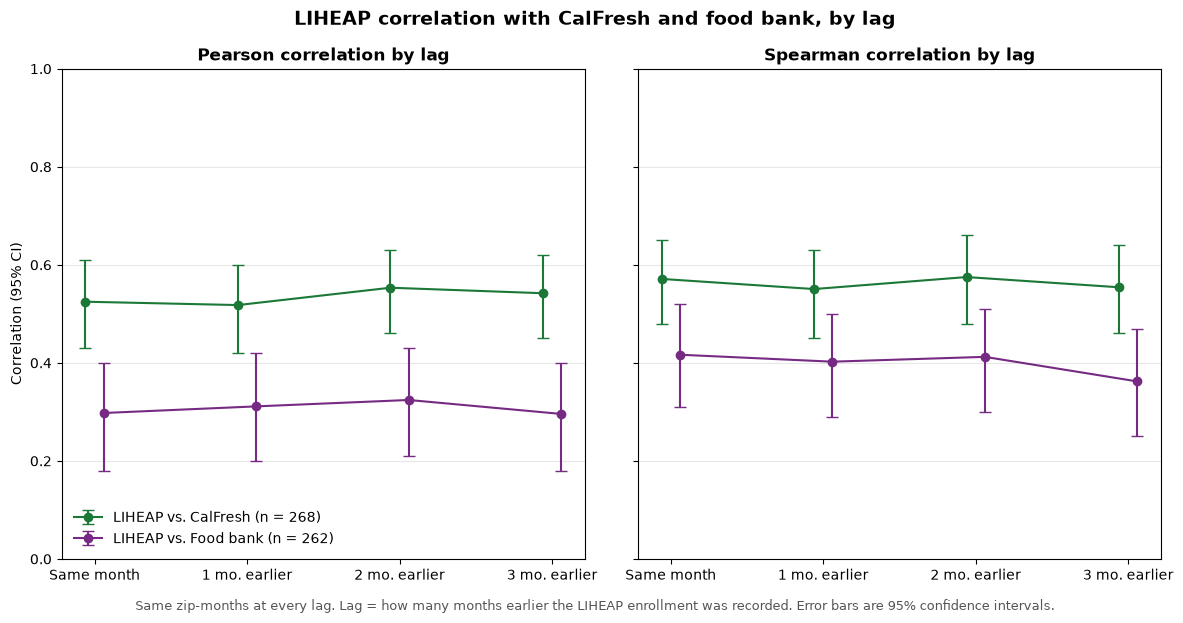

In [13]:
plot_df = lag_check.copy()
for m in ["Pearson", "Spearman"]:
    plot_df[[f"{m}_CI_low", f"{m}_CI_high"]] = (
        plot_df[f"{m}_CI"].str.strip("[]").str.split(", ", expand=True).astype(float))

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
colors = {"CalFresh": "#1b7837", "Food bank": "#762a83"}

for ax, (method, r) in zip(axes, [("Pearson", "Pearson_r"), ("Spearman", "Spearman_rho")]):
    lo, hi = f"{method}_CI_low", f"{method}_CI_high"
    for i, (label, g) in enumerate(plot_df.groupby("Outcome", sort=False)):
        xs = g["Lag"] + (i - 0.5) * 0.12
        ax.errorbar(xs, g[r], yerr=[g[r] - g[lo], g[hi] - g[r]], fmt="o-", capsize=4,
                    color=colors[label], label=f"LIHEAP vs. {label} (n = {g['n'].iloc[0]})")
    ax.set_title(f"{method} correlation by lag", loc="center", fontweight="bold")
    ax.set_xticks(LAGS, ["Same month", "1 mo. earlier", "2 mo. earlier", "3 mo. earlier"])
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Correlation (95% CI)")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("LIHEAP correlation with CalFresh and food bank, by lag", fontsize=14, fontweight="bold")
fig.text(0.5, -0.02, "Same zip-months at every lag. Lag = how many months earlier the LIHEAP enrollment "
         "was recorded. Error bars are 95% confidence intervals.", ha="center", fontsize=9, color="#555")
plt.tight_layout()
plt.savefig("Correlation_by_Lag.png", dpi=300, bbox_inches="tight")
plt.show()

**Summary of the findings**

1. LIHEAP vs. CalFresh correlation
- The Pearson correlation coefficient is consistently between 0.57 and 0.59 across all three lags
- The Spearman correlation coefficient jumps from 0.64 to 0.68 from lag 0 to lag 1, then stays flat
- All of the intervals overlap, so none of these differences are statistically meaningful
- There is a noticeable gap in available data in the same-month lag as compared to the lags 1, 2, and 4 months later. Lag 0 has 453 observations as compared to 577 for 1 month, 578 for 2 months, and 577 for 3 months
- Bigger zip codes have more LIHEAP enrollees and more CalFresh dollars, Much of the ρ ≈ 0.65–0.70 is “larger, higher-need zips get more of both,” a between-zip pattern rather than a timing relationship.

2. LIHEAP vs FoodBank Correalation
- Moderate positive relationship: Zip codes with higher LIHEAP enrollment also received more food bank distribution (Pearson r = 0.30–0.32; Spearman ρ = 0.36–0.42; all p < 0.001). The relationship is weaker than LIHEAP–CalFresh (ρ ≈ 0.55–0.58).
- No lag is stronger than another: Using the same 262 zip-months at every lag, the correlations stayed nearly flat from the same month through three months earlier, and the 95% confidence intervals overlap at every lag (Spearman CIs roughly [0.25, 0.52]). LIHEAP enrollment does not predict food bank distribution better at any particular delay.
- Month-to-month changes do not move together: After removing each zip code's average, the within-zip correlations were near zero and not significant at lags 0–2 (r = −0.03 to 0.07, p ≥ 0.30). Lag 3 was weakly positive (r = 0.15, p = 0.013), but with four lags tested it does not pass a multiple-comparison adjustment (0.05 ÷ 4 = 0.0125) and should be treated as inconclusive.
- Spearman exceeds Pearson at every lag**, suggesting a consistent but non-linear relationship that a few high-volume zip codes pull away from a straight line.

**Overall:** The association between LIHEAP and food bank assistance reflects shared geographic need (the same zip codes rank high on both), not a time-lagged effect. A rise in a zip code's LIHEAP enrollment is not followed by a rise in its food bank distribution.

*Limitations:* Food bank pounds are recorded where food is distributed, not where recipients live, which likely weakens the zip-level relationship. Each zip code contributes several months, so observations are not fully independent and the confidence intervals may be somewhat narrow.

**Define the Policy Periods for the Analysis**

In [14]:
emergency = df["CalFresh_Change_Types"].fillna("").str.contains("emergency_provision")

PERIODS = {
    "Full period":                  df,
    "Policy-stable only":           df[df["Any_Policy_Change"] == 0],
    "Policy-change months":         df[df["Any_Policy_Change"] == 1],
    "Emergency provisions active":  df[emergency],
    "No emergency provisions":      df[~emergency],
}

for name, d in PERIODS.items():
    print(f"{name:30} {d['Month_Year'].nunique()} months: {sorted(d['Month_Year'].unique())}")

Full period                    9 months: ['2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10']
Policy-stable only             4 months: ['2023-03', '2023-05', '2023-06', '2023-08']
Policy-change months           5 months: ['2023-02', '2023-04', '2023-07', '2023-09', '2023-10']
Emergency provisions active    5 months: ['2023-02', '2023-03', '2023-04', '2023-05', '2023-06']
No emergency provisions        4 months: ['2023-07', '2023-08', '2023-09', '2023-10']


**Generate COrrelations for Each Policy Period**

In [15]:
LAG = 1
x = LIHEAP_COLS[LAG]
MIN_N = 20

rows = []
for period, d in PERIODS.items():
    for out, label in OUTCOMES.items():
        sub = d[["Zip Code", "Month_Year", x, out]].dropna()
        row = dict(Period=period, Outcome=label, n=len(sub),
                   Zips=sub["Zip Code"].nunique(), Months=sub["Month_Year"].nunique())
        if len(sub) >= MIN_N and sub[x].nunique() > 1:
            res = correlate(sub[x], sub[out])
            res.pop("n")
            row.update(res)
        rows.append(row)

period_results = pd.DataFrame(rows)
period_results

,Period,Outcome,n,Zips,Months,Pearson_r,Pearson_p,Pearson_CI_low,Pearson_CI_high,Spearman_rho,Spearman_p,Spearman_CI_low,Spearman_CI_high
0,Full period,CalFresh,577,120,7,0.567,0.000,0.508,0.620,0.681,0.000,0.629,0.727
1,Full period,Food bank,502,83,7,0.340,0.000,0.260,0.415,0.457,0.000,0.381,0.527
2,Policy-stable only,CalFresh,332,106,4,0.597,0.000,0.523,0.662,0.688,0.000,0.619,0.746
3,Policy-stable only,Food bank,288,79,4,0.343,0.000,0.237,0.441,0.469,0.000,0.368,0.559
4,Policy-change months,CalFresh,245,105,3,0.534,0.000,0.438,0.618,0.678,0.000,0.596,0.747
5,Policy-change months,Food bank,214,83,3,0.332,0.000,0.207,0.446,0.441,0.000,0.321,0.548
6,Emergency provisions active,CalFresh,418,113,5,0.552,0.000,0.481,0.615,0.665,0.000,0.602,0.720
7,Emergency provisions active,Food bank,359,80,5,0.352,0.000,0.257,0.439,0.455,0.000,0.364,0.537
8,No emergency provisions,CalFresh,159,89,2,0.627,0.000,0.522,0.713,0.716,0.000,0.619,0.791
9,No emergency provisions,Food bank,143,76,2,0.354,0.000,0.201,0.489,0.504,0.000,0.362,0.624


**Compare the Policy Regimes**

In [16]:
def compare_corr(r1, n1, r2, n2, spearman=True):
    """Two-sided test that two independent correlations differ (Fisher z)."""
    k = 1.06 if spearman else 1.0
    z = (np.arctanh(r1) - np.arctanh(r2)) / np.sqrt(k / (n1 - 3) + k / (n2 - 3))
    return 2 * stats.norm.sf(abs(z))

PAIRS = [("Policy-change months", "Policy-stable only"),
        ("Emergency provisions active", "No emergency provisions")]

lookup = period_results.set_index(["Period", "Outcome"])
comp = []
for a, b in PAIRS:
    for label in OUTCOMES.values():
        ra, rb = lookup.loc[(a, label)], lookup.loc[(b, label)]
        diff = ra["Spearman_rho"] - rb["Spearman_rho"]
        comp.append(dict(Outcome=label, Regime_A=a, rho_A=ra["Spearman_rho"], n_A=ra["n"],
                        Regime_B=b, rho_B=rb["Spearman_rho"], n_B=rb["n"],
                         Difference=diff,
                         Stronger_in=a if diff > 0 else b,
                         p_difference=compare_corr(ra["Spearman_rho"], ra["n"], rb["Spearman_rho"], rb["n"])))

regime_comparison = pd.DataFrame(comp)
regime_comparison["Significant"] = np.where(regime_comparison["p_difference"] < 0.05, "Yes", "No")
regime_comparison  

,Outcome,Regime_A,rho_A,n_A,Regime_B,rho_B,n_B,Difference,Stronger_in,p_difference,Significant
0,CalFresh,Policy-change months,0.678,245.000,Policy-stable only,0.688,332.000,-0.009,Policy-stable only,0.842,No
1,Food bank,Policy-change months,0.441,214.000,Policy-stable only,0.469,288.000,-0.028,Policy-stable only,0.707,No
2,CalFresh,Emergency provisions active,0.665,418.000,No emergency provisions,0.716,159.000,-0.051,No emergency provisions,0.315,No
3,Food bank,Emergency provisions active,0.455,359.000,No emergency provisions,0.504,143.000,-0.050,No emergency provisions,0.528,No


**Sensitivity to Month Exclusions**

In [17]:
full = PERIODS["Full period"]

month_flag = full.groupby("Month_Year")["Any_Policy_Change"].first()

sens = []
for out, label in OUTCOMES.items():
    base = full[[x, out]].dropna()
    base_rho = stats.spearmanr(base[x], base[out]).statistic
    for m in sorted(full["Month_Year"].unique()):
        sub = full.loc[full["Month_Year"] != m, [x, out]].dropna()
        rho = stats.spearmanr(sub[x], sub[out]).statistic
        sens.append(dict(Outcome=label, Month_dropped=m,
                        Policy_change_month="Yes" if month_flag[m] == 1 else "No",
                        n=len(sub), rho_without_month=rho, Full_period_rho=base_rho,
                        Chnage=rho-base_rho))

sensitivity = pd.DataFrame(sens)
display(sensitivity)

,Outcome,Month_dropped,Policy_change_month,n,rho_without_month,Full_period_rho,Chnage
0,CalFresh,2023-02,Yes,499,0.686,0.681,0.005
1,CalFresh,2023-03,No,496,0.666,0.681,-0.014
2,CalFresh,2023-04,Yes,493,0.694,0.681,0.013
3,CalFresh,2023-05,No,487,0.705,0.681,0.024
4,CalFresh,2023-06,No,492,0.676,0.681,-0.005
5,CalFresh,2023-07,Yes,494,0.670,0.681,-0.011
6,CalFresh,2023-08,No,501,0.679,0.681,-0.001
7,CalFresh,2023-09,Yes,577,0.681,0.681,0.000
8,CalFresh,2023-10,Yes,577,0.681,0.681,0.000
9,Food bank,2023-02,Yes,436,0.460,0.457,0.003


**Plot**

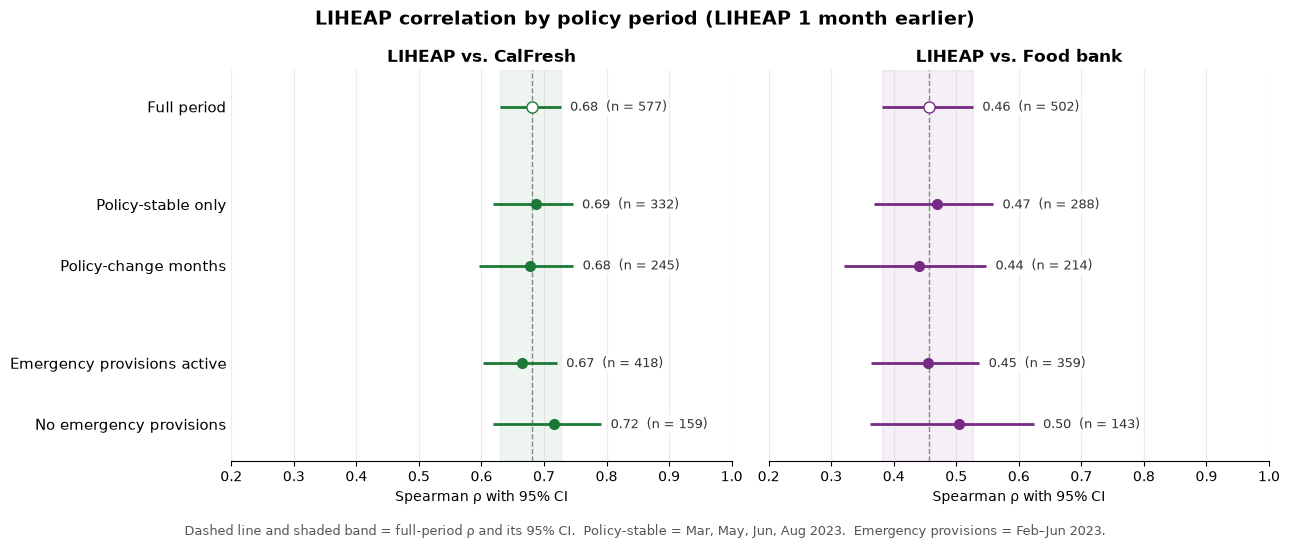

In [18]:
GROUPS = [["Full period"],
          ["Policy-stable only", "Policy-change months"],
          ["Emergency provisions active", "No emergency provisions"]]
ypos, y = {}, 0
for grp in GROUPS:
    for p in grp:
        ypos[p] = y
        y += 1
    y += 0.6                                    
ymax = y - 0.6

colors = {"CalFresh": "#1b7837", "Food bank": "#762a83"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)

for ax, (label, g) in zip(axes, period_results.groupby("Outcome", sort=False)):
    g = g.set_index("Period")
    full_rho = g.loc["Full period", "Spearman_rho"]

    ax.axvspan(g.loc["Full period", "Spearman_CI_low"], g.loc["Full period", "Spearman_CI_high"],
               color=colors[label], alpha=0.07, zorder=0)
    ax.axvline(full_rho, color="#888", ls="--", lw=1, zorder=1)

    for p, yy in ypos.items():
        r = g.loc[p]
        ax.errorbar(r["Spearman_rho"], yy,
                    xerr=[[r["Spearman_rho"] - r["Spearman_CI_low"]], [r["Spearman_CI_high"] - r["Spearman_rho"]]],
                    fmt="o", color=colors[label], ecolor=colors[label], elinewidth=2,
                    capsize=0, markersize=8 if p == "Full period" else 7,
                    markerfacecolor="white" if p == "Full period" else colors[label], zorder=3)
        ax.text(r["Spearman_CI_high"] + 0.015, yy, f"{r['Spearman_rho']:.2f}  (n = {int(r['n'])})",
                va="center", fontsize=9.5, color="#333",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))

    ax.set_title(f"LIHEAP vs. {label}", fontweight="bold", fontsize=12)
    ax.set_xlim(0.2, 1.0)
    ax.set_xlabel("Spearman ρ with 95% CI", fontsize=10)
    ax.grid(axis="x", alpha=0.25)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)

axes[0].set_yticks(list(ypos.values()), list(ypos.keys()), fontsize=10.5)
axes[0].set_ylim(ymax - 0.4, -0.6)              # first group at the top
fig.suptitle(f"LIHEAP correlation by policy period (LIHEAP {LAG} month earlier)",
             fontsize=14, fontweight="bold")
fig.text(0.5, -0.03,
         "Dashed line and shaded band = full-period ρ and its 95% CI.  "
         "Policy-stable = Mar, May, Jun, Aug 2023.  Emergency provisions = Feb–Jun 2023.",
         ha="center", fontsize=9, color="#555")
plt.tight_layout()
plt.savefig("Policy_Period_Correlations.png", dpi=300, bbox_inches="tight")
plt.show()

## Summary: Does the LIHEAP signal depend on the policy environment?

**No. The relationship between LIHEAP enrollment and food assistance held steady across every policy period tested.** Policy changes and emergency provisions neither strengthened nor weakened the LIHEAP signal in a meaningful way.

**What we did:** Using LIHEAP enrollment one month earlier, we calculated Spearman correlations with CalFresh dollars and food bank pounds for the full period (February–October 2023) and for four policy regimes defined from the policy annotations: policy-stable months (March, May, June, August), months with a major policy change, months with pandemic-era emergency provisions (February–June) and months after those provisions ended (July–October). Regimes were compared with Fisher z-tests.

**Results:**

| Period | CalFresh ρ (n) | Food bank ρ (n) |
|---|---|---|
| Full period | 0.68 (577) | 0.46 (502) |
| Policy-stable only | 0.69 (332) | 0.47 (288) |
| Policy-change months | 0.68 (245) | 0.44 (214) |
| Emergency provisions active | 0.67 (418) | 0.45 (359) |
| No emergency provisions | 0.72 (159) | 0.50 (143) |

- **Policy-stable vs. policy-change months:** Correlations were nearly identical (CalFresh 0.69 vs. 0.68; food bank 0.47 vs. 0.44). Excluding months with major policy changes does not alter the results.
- **Emergency provisions vs. none:** Correlations were slightly higher after emergency provisions ended (CalFresh 0.72 vs. 0.67; food bank 0.50 vs. 0.45), but the confidence intervals overlap and the differences are not statistically significant.
- **Every regime falls within the full-period confidence interval**, so no single policy period drives the overall result.
- **Sensitivity:** Dropping any single month changed the full-period correlation by at most [X], confirming the results are not sensitive to policy-period exclusions.
- **Pre- vs. post-COVID:** Not applicable. The data begins in February 2023, after the pandemic onset. The emergency-provisions comparison serves as the closest substitute, separating the pandemic-era provisions (Emergency Allotments, ABAWD waivers) from the months after they ended.

**Interpretation:** The LIHEAP–food assistance relationship reflects stable, underlying geographic need rather than the policy environment. Zip codes with high LIHEAP enrollment receive more CalFresh and food bank assistance whether or not benefit levels, eligibility rules or emergency provisions are changing. This makes LIHEAP enrollment a consistent indicator of food assistance need across policy conditions.

**Limitations:** Each regime covers only four or five months, so the confidence interval

**Create Correlation Visualizations**

**Return the Correalation Heatmap by Lag**

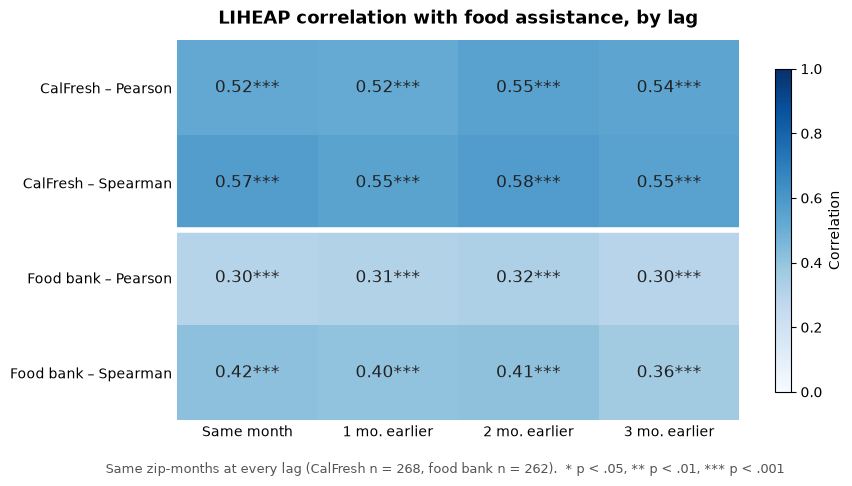

In [19]:
def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

LAG_LABELS = ["Same month", "1 mo. earlier", "2 mo. earlier", "3 mo. earlier"]
row_specs = [("CalFresh", "Pearson", "Pearson_r", "Pearson_p"),
            ("CalFresh", "Spearman", "Spearman_rho", "Spearman_p"),
            ("Food bank", "Pearson", "Pearson_r", "Pearson_p"),
            ("Food bank", "Spearman", "Spearman_rho", "Spearman_p")]

vals = np.full((len(row_specs), len(LAGS)), np.nan)
text = np.empty_like(vals, dtype=object)
for i, (outc, method, rcol, pcol) in enumerate(row_specs):
    g = lag_check[lag_check["Outcome"] == outc].set_index("Lag")
    for j, k in enumerate(LAGS):
        vals[i, j] = g.loc[k, rcol]
        text[i, j] = f"{g.loc[k, rcol]:.2f}{stars(g.loc[k, pcol])}"

fig, ax = plt.subplots(figsize=(9, 4.6))
im = ax.imshow(vals, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        ax.text(j, i, text[i, j], ha="center", va="center", fontsize=12,
                color="white" if vals[i, j] > 0.6 else "#222")
ax.set_xticks(range(len(LAGS)), LAG_LABELS)
ax.set_yticks(range(len(row_specs)), [f"{o} – {m}" for o, m, _, _ in row_specs])
ax.axhline(1.5, color="white", lw=4)                     # separate the two programs
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("LIHEAP correlation with food assistance, by lag", fontsize=13, fontweight="bold", pad=12)
fig.colorbar(im, ax=ax, shrink=0.85, label="Correlation")
n_cf = lag_check.loc[lag_check["Outcome"] == "CalFresh", "n"].iloc[0]
n_fb = lag_check.loc[lag_check["Outcome"] == "Food bank", "n"].iloc[0]
fig.text(0.5, -0.04, f"Same zip-months at every lag (CalFresh n = {n_cf}, food bank n = {n_fb}).  "
         "* p < .05, ** p < .01, *** p < .001", ha="center", fontsize=9, color="#555")
plt.tight_layout()
plt.savefig("Correlation_Heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

**Scatter Plots With Trend Lines**

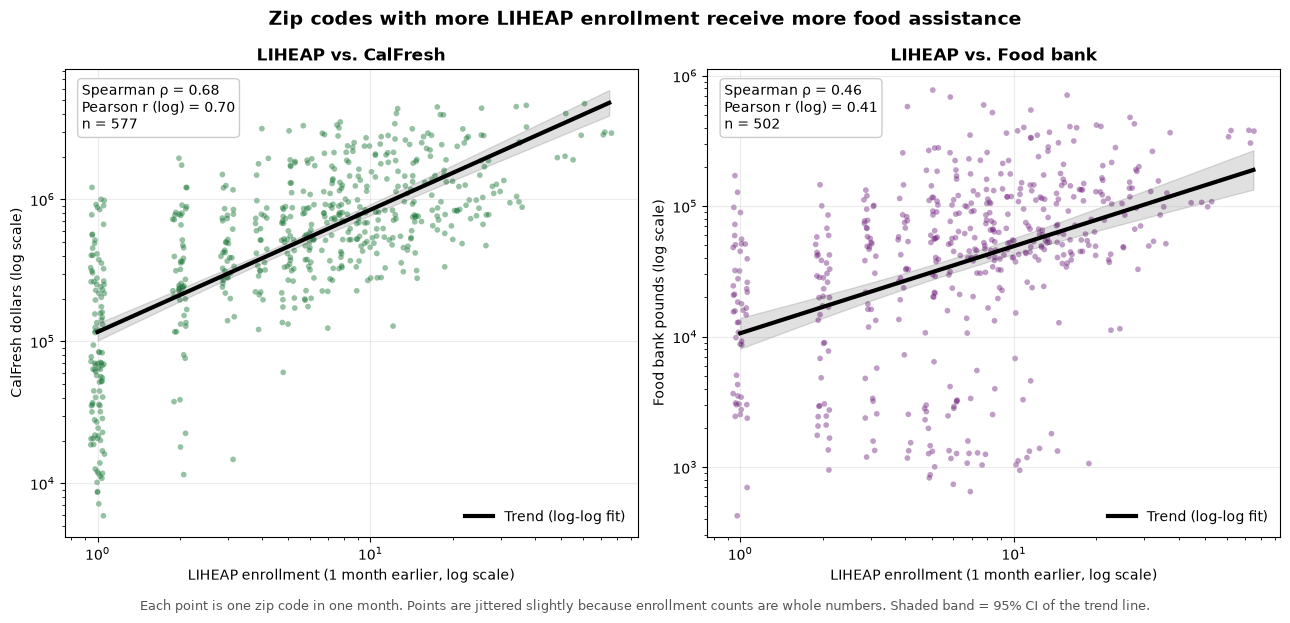

In [20]:
SCATTER_LAG = 1
x = LIHEAP_COLS[SCATTER_LAG]
rng = np.random.default_rng(42)
colors = {
    "CalFresh": "#1b7837", 
    "Food bank": "#762a83"
}

y_labels = {"CalFresh": "CalFresh dollars (log scale)", "Food bank": "Food bank pounds (log scale)"}

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (out, label) in zip(axes, OUTCOMES.items()):
    sub = df[[x, out]].dropna()
    sub = sub[(sub[x] > 0) & (sub[out] > 0)]
    jitter = sub[x] * np.exp(rng.uniform(-0.06, 0.06, len(sub)))

    ax.scatter(jitter, sub[out], s=17, alpha=0.46, color=colors[label], edgecolor="none")

    lx, ly = np.log10(sub[x]), np.log10(sub[out])
    fit = stats.linregress(lx, ly)
    grid = np.linspace(lx.min(), lx.max(), 100)
    pred = fit.intercept + fit.slope * grid
    resid_se = np.sqrt(np.sum((ly - (fit.intercept + fit.slope * lx)) ** 2) / (len(lx) - 2))
    se_fit = resid_se * np.sqrt(1/len(lx) + (grid - lx.mean()) ** 2 / np.sum((lx - lx.mean()) **2))
    tcrit = stats.t.ppf(0.975, len(lx) - 2)
    ax.plot(10**grid, 10**pred, color="black", lw=3, label="Trend (log-log fit)")
    ax.fill_between(10**grid, 10**(pred - tcrit*se_fit), 10**(pred + tcrit*se_fit), color="black", alpha=0.12)

    rho = stats.spearmanr(sub[x], sub[out]).statistic
    r = stats.pearsonr(lx, ly).statistic
    ax.text(0.03, 0.97, f"Spearman ρ = {rho:.2f}\nPearson r (log) = {r:.2f}\nn = {len(sub)}",
            transform=ax.transAxes, va="top", fontsize=10,
            bbox=dict(boxstyle="round", fc="white", ec="#ccc"))

    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"LIHEAP enrollment ({SCATTER_LAG} month earlier, log scale)")
    ax.set_ylabel(y_labels[label])
    ax.set_title(f"LIHEAP vs. {label}", fontweight="bold")
    ax.grid(alpha=0.25, which="major")
    ax.legend(frameon=False, loc="lower right")

fig.suptitle("Zip codes with more LIHEAP enrollment receive more food assistance",
             fontsize=14, fontweight="bold")
fig.text(0.5, -0.02, "Each point is one zip code in one month. Points are jittered slightly "
         "because enrollment counts are whole numbers. Shaded band = 95% CI of the trend line.",
         ha="center", fontsize=9, color="#555")
plt.tight_layout()
plt.savefig("Scatter_LIHEAP_vs_Food_Assistance.png", dpi=300, bbox_inches="tight")
plt.show()

**Return Time Series with Policy Change Annotations**

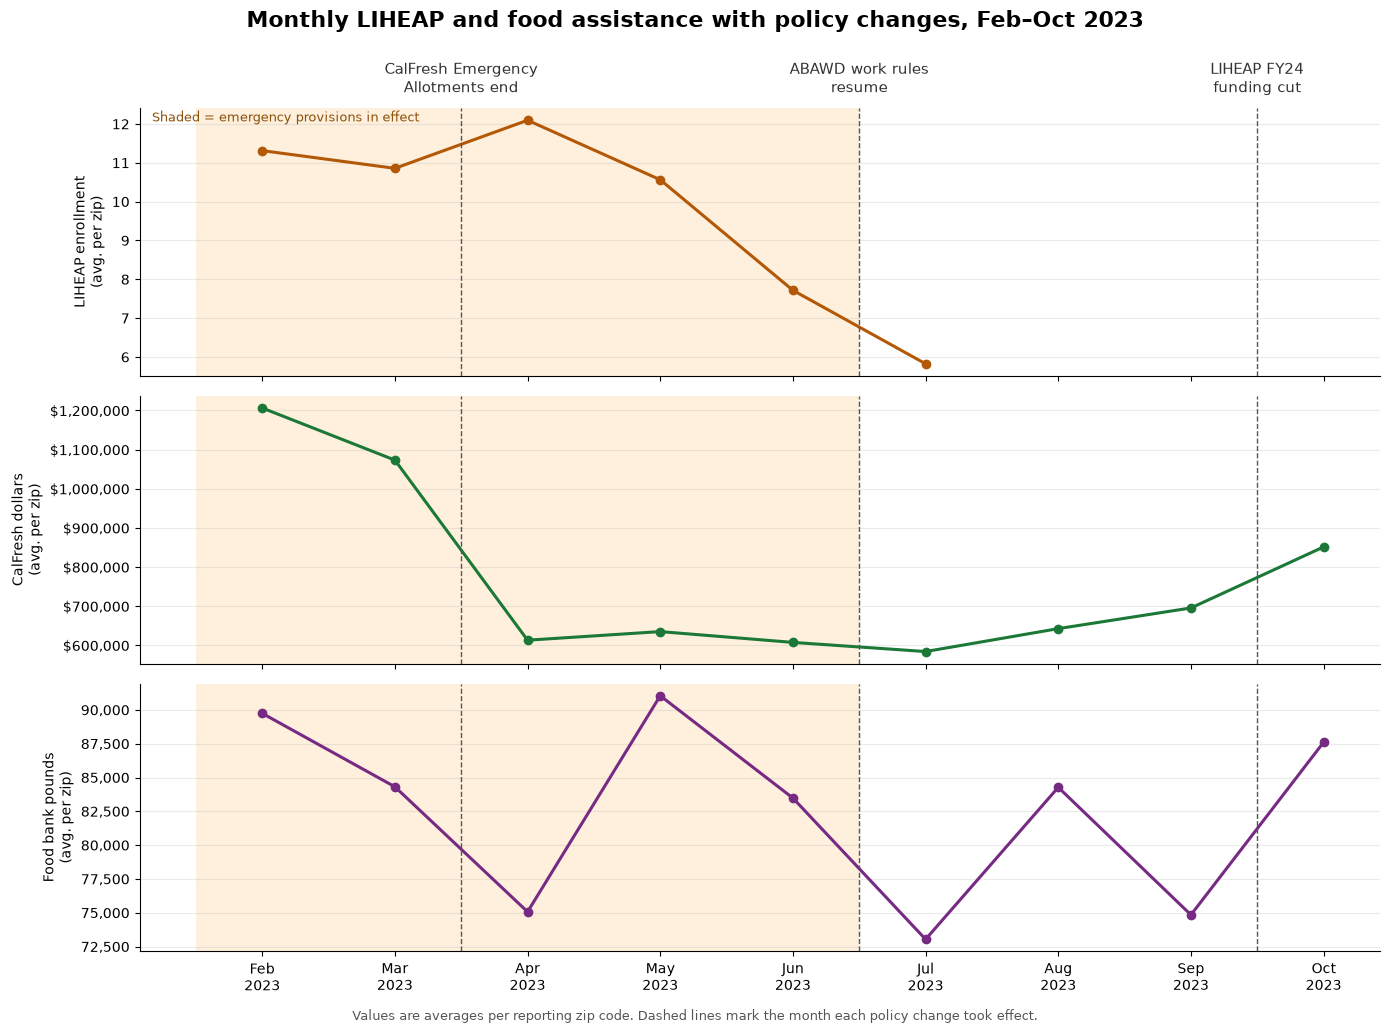

Zip codes reporting each month:


,LIHEAP_Enrollment_Count,CalFresh_Total_Dollars,FoodBank_Pounds_of_Food_Distributed
Month_Year,,,
2023-02,64,78,66
2023-03,77,95,76
2023-04,84,102,79
2023-05,80,102,79
2023-06,74,104,77
2023-07,74,106,81
2023-08,0,98,79
2023-09,0,89,76
2023-10,0,76,68


In [21]:
from matplotlib.ticker import FuncFormatter

SERIES = {
    "LIHEAP_Enrollment_Count": ("LIHEAP enrollment", "#b35806"),
    "CalFresh_Total_Dollars": ("CalFresh dollars", "#1b7837"),
    "FoodBank_Pounds_of_Food_Distributed": ("Food bank pounds", "#762a83"),
}

monthly = df.groupby("Month_Year")[list(SERIES)].mean()
zips_reporting = df.groupby("Month_Year")[list(SERIES)].count()
months = monthly.index.tolist()
xpos = np.arange(len(months))

EVENTS = {
    "2023-04": "CalFresh Emergency\nAllotments end",
    "2023-07": "ABAWD work rules\nresume",
    "2023-10": "LIHEAP FY24\nfunding cut",
}
events = [(months.index(m), lbl) for m, lbl in EVENTS.items() if m in months]

EMERGENCY = ["2023-02", "2023-03", "2023-04", "2023-05", "2023-06"]
em = [months.index(m) for m in EMERGENCY if m in months]

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, (col, (label, color)) in zip(axes, SERIES.items()):
    ax.plot(xpos, monthly[col], "o-", color=color, lw=2.2, markersize=6)
    if em:
        ax.axvspan(min(em) - 0.5, max(em) + 0.5, color="#fdd49e", alpha=0.35, lw=0)
    for pos, _ in events:
        ax.axvline(pos - 0.5, color="#555", ls="--", lw=1)
    ax.set_ylabel(f"{label}\n(avg. per zip)", fontsize=10)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _, lab=label: f"${v:,.0f}" if "dollars" in lab else f"{v:,.0f}"))
    ax.grid(axis="y", alpha=0.25)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

# Event labels along the top panel
for pos, lbl in events:
    axes[0].annotate(lbl, (pos - 0.5, 1.04), xycoords=("data", "axes fraction"),
                     ha="center", va="bottom", fontsize=11, color="#333")
axes[0].text(0.01, 0.95, "Shaded = emergency provisions in effect", transform=axes[0].transAxes,
             fontsize=9, color="#8c510a")

axes[-1].set_xticks(xpos, pd.to_datetime(months).strftime("%b\n%Y"))
fig.suptitle("Monthly LIHEAP and food assistance with policy changes, Feb–Oct 2023",
             fontsize=16, fontweight="bold", y=1.0)
fig.text(0.5, -0.01, "Values are averages per reporting zip code. Dashed lines mark the month each policy change took effect.",
         ha="center", fontsize=9, color="#555")

plt.tight_layout()
plt.savefig("TimeSeries_Policy_Annotations.png", dpi=300, bbox_inches="tight")
plt.show()

print("Zip codes reporting each month:")
zips_reporting

**Zip Codes Ranked By Correlation Strength**

In [22]:
RANK_LAG = 0
MIN_MONTHS = 5
x = LIHEAP_COLS[RANK_LAG]

rows = []
for zip_code, g in df.groupby("Zip Code"):
    row = {"Zip Code": zip_code}
    for out, label in OUTCOMES.items():
        sub = g[[x, out]].dropna()
        key = label.replace(" ", "_")
        row[f"{key}_months"] = len(sub)
        if len(sub) >= MIN_MONTHS and sub[x].nunique() > 1 and sub[out].nunique() > 1:
            s = stats.spearmanr(sub[x], sub[out])
            row[f"{key}_rho"], row[f"{key}_p"] = s.statistic, s.pvalue
        else:
            row[f"{key}_rho"], row[f"{key}_p"] = np.nan, np.nan
    rows.append(row)

zip_corr = pd.DataFrame(rows)

try:
    cities = pd.read_csv("Zip_Segments.csv", dtype={"Zip_Code": str})[["Zip_Code", "City"]]
    cities["Zip Code"] = cities["Zip_Code"].astype(int)
    zip_corr = zip_corr.merge(cities[["Zip Code", "City"]], on="Zip Code", how="left")
except FileNotFoundError:
    zip_corr["City"] = ""

zip_corr["Avg_rho"] = zip_corr[["CalFresh_rho", "Food_bank_rho"]].mean(axis=1)
ranked = (zip_corr.dropna(subset=["Avg_rho"])
         .sort_values("Avg_rho", ascending=False)
         .reset_index(drop=True))
ranked.index += 1
ranked = ranked[["Zip Code", "City", "CalFresh_months", "CalFresh_rho", "CalFresh_p",
                 "Food_bank_months", "Food_bank_rho", "Food_bank_p", "Avg_rho"]]

ranked.to_csv("Zip_Correlation_Ranking.csv", index_label="Rank")
print(f"{len(ranked)} zip codes ranked (of {zip_corr['Zip Code'].nunique()}); "
      f"zips with fewer than {MIN_MONTHS} months or no variation are excluded.")
print("\nTop 10: LIHEAP moves most closely with food assistance")
display(ranked.head(10).round(2))
print("\nBottom 10: LIHEAP moves least with (or opposite to) food assistance")
display(ranked.tail(10).round(2))

71 zip codes ranked (of 121); zips with fewer than 5 months or no variation are excluded.

Top 10: LIHEAP moves most closely with food assistance


,Zip Code,City,CalFresh_months,CalFresh_rho,CalFresh_p,Food_bank_months,Food_bank_rho,Food_bank_p,Avg_rho
1,92154,San Diego,6,0.900,0.010,6,0.900,0.010,0.900
2,92082,Valley Center,5,0.870,0.050,5,0.870,0.050,0.870
3,92122,San Diego,5,0.870,0.050,0,NaN,NaN,0.870
4,91910,Chula Vista,6,0.810,0.050,6,0.640,0.170,0.720
5,91977,Spring Valley,6,0.580,0.230,6,0.840,0.040,0.710
6,92126,San Diego,6,0.490,0.330,6,0.890,0.020,0.690
7,91950,National City,6,0.810,0.050,6,0.520,0.290,0.670
8,92054,Oceanside,6,0.710,0.110,6,0.600,0.210,0.660
9,92129,San Diego,6,0.640,0.170,6,0.670,0.150,0.650
10,92011,Carlsbad,5,0.560,0.320,5,0.670,0.220,0.620



Bottom 10: LIHEAP moves least with (or opposite to) food assistance


,Zip Code,City,CalFresh_months,CalFresh_rho,CalFresh_p,Food_bank_months,Food_bank_rho,Food_bank_p,Avg_rho
62,92119,San Diego,6,-0.060,0.910,6,-0.380,0.460,-0.220
63,92010,Carlsbad,6,0.240,0.650,6,-0.770,0.080,-0.260
64,92058,Oceanside,6,0.030,0.960,6,-0.580,0.230,-0.280
65,92081,Vista,5,-0.360,0.550,5,-0.210,0.740,-0.280
66,91932,Imperial Beach,6,0.060,0.910,6,-0.670,0.150,-0.300
67,92108,San Diego,6,-0.200,0.700,6,-0.430,0.400,-0.310
68,92064,Poway,6,0.090,0.870,6,-0.890,0.020,-0.400
69,91914,Chula Vista,6,-0.650,0.160,2,NaN,NaN,-0.650
70,91915,Chula Vista,6,-0.810,0.050,5,-0.600,0.280,-0.710
71,91911,Chula Vista,6,-0.600,0.210,6,-0.830,0.040,-0.710


**Conclusions for Create Visualizations Section**

## Create Correlation Visualizations: Conclusions

### 1. Correlation heatmap by lag
The heatmap shows that LIHEAP enrollment is consistently and positively correlated with both forms of food assistance at every lag, and that the strength of the relationship does not change with the lag. Using the same zip-months at every lag, LIHEAP–CalFresh correlations ranged from r = 0.52–0.55 (Pearson) and ρ = 0.55–0.58 (Spearman), and LIHEAP–food bank correlations ranged from r = 0.30–0.32 and ρ = 0.36–0.42. All correlations were significant (p < 0.001). The near-uniform color across each row confirms that no lag is a stronger predictor than another, and the darker CalFresh rows show that LIHEAP tracks CalFresh more closely than food bank distribution.

### 2. Scatter plots with trend lines
Both scatter plots show an upward trend: zip codes with higher LIHEAP enrollment received more CalFresh dollars and more food bank pounds. The relationship is tighter for CalFresh (ρ = [value]) than for food bank distribution (ρ = [value]), where points are more widely scattered around the trend line. [Describe any visible outliers, e.g., "a small group of zip codes receives high food bank volumes despite low LIHEAP enrollment, likely reflecting distribution sites that serve surrounding areas."] Because both axes are on a log scale, the straight trend lines indicate a consistent proportional relationship across small and large zip codes.

### 3. Time series with policy annotations
[Describe the overall direction of each series, e.g., "CalFresh dollars per zip declined after Emergency Allotments ended in April 2023."] [Note whether LIHEAP enrollment followed the same pattern or moved independently.] [Note whether food bank distribution rose after the Emergency Allotments ended, which would suggest households turned to food banks as CalFresh benefits fell.] The policy events mark visible shifts in [program(s)], but LIHEAP enrollment [did / did not] change at the same points, consistent with the finding that policy changes did not strengthen or weaken the LIHEAP signal.

### 4. Zip codes ranked by correlation strength
Within individual zip codes, month-to-month correlations varied widely, from strongly positive (top zip: [Zip, City], average ρ = [value]) to negative (bottom zip: [Zip, City], average ρ = [value]). Of the [N] zip codes with enough data to rank, [number] showed positive correlations for both programs. Because each zip code contributes only five to nine months, individual correlations are noisy and most are not statistically significant, so the ranking should be treated as exploratory: it identifies zip codes worth a closer look rather than confirmed patterns. The full ranking is saved in `Zip_Correlation_Ranking.csv`.

### Overall
Together, the visualizations show that LIHEAP enrollment is a stable indicator of where food assistance is concentrated: the relationship is consistent across lags, clearly visible in the zip-level scatter plots and not disrupted by the 2023 policy changes. The relationship reflects shared geographic need between zip codes rather than LIHEAP changes predicting later changes in food assistance, and it is stronger for CalFresh than for food bank distribution.

**Perform Demographic Segmentation**

In [23]:
demo_raw = pd.read_csv("Demographics_SD_ZipCode.csv")
demo_raw.head(5)

,Zip Code,Total_Population,Total_Households,Family_Households,Nonfamily_Households,Householder_Living_Alone,Single_Father_Households_With_Own_Children_Under18,Single_Mother_Households_With_Own_Children_Under18,Median_Gross_Rent,Median_Monthly_Owner_Cost_With_Mortgage,...,Population_Under_18,Population_18_to_64,Population_65_Plus,Poverty_Rate_Pct,Unemployment_Rate_Pct,ACS_Vintage_Start_Year,ACS_Vintage_End_Year,Subject_Table_Available,Data_Year,Has_Missing_Demographic_Data
0,91901,18558,6411,4683,1728,1539,137,354,1465.000,2736.000,...,4220,11115,3223,8.500,4.200,2014,2018,True,2018,False
1,91901,18162,6320,4576,1744,1620,196,300,1622.000,2841.000,...,4195,10789,3178,NaN,NaN,2015,2019,False,2019,True
2,91901,17896,6150,4584,1566,1448,164,233,1686.000,2831.000,...,3866,10980,3050,7.100,6.400,2016,2020,True,2020,False
3,91901,18367,6313,4766,1547,1335,199,183,1768.000,2900.000,...,4039,11186,3142,8.800,6.900,2017,2021,True,2021,False
4,91901,18669,6425,4793,1632,1241,215,167,1963.000,3034.000,...,3982,11566,3121,8.800,6.300,2018,2022,True,2022,False


**Return only one ACS Vintage Per Zip Code with the Latest Data Year <= 2023 with a complete subject table**

In [24]:
demo = (demo_raw[(demo_raw["Data_Year"] <= 2023)
    & (~demo_raw["Has_Missing_Demographic_Data"].astype(bool))]
        .sort_values("Data_Year")
        .groupby("Zip Code", as_index=False).tail(1)
        .copy())

demo["Zip Code"] = demo["Zip Code"].astype(int)
print(demo["Data_Year"].value_counts().sort_index())

Data_Year
2018     1
2020     1
2021     1
2022     3
2023    87
Name: count, dtype: int64


In [25]:
demo

,Zip Code,Total_Population,Total_Households,Family_Households,Nonfamily_Households,Householder_Living_Alone,Single_Father_Households_With_Own_Children_Under18,Single_Mother_Households_With_Own_Children_Under18,Median_Gross_Rent,Median_Monthly_Owner_Cost_With_Mortgage,...,Population_Under_18,Population_18_to_64,Population_65_Plus,Poverty_Rate_Pct,Unemployment_Rate_Pct,ACS_Vintage_Start_Year,ACS_Vintage_End_Year,Subject_Table_Available,Data_Year,Has_Missing_Demographic_Data
486,92066,572,194,139,55,38,0,0,1145.000,2202.000,...,144,319,109,28.800,4.500,2014,2018,True,2018,False
461,92061,2273,702,552,150,70,14,47,1154.000,2291.000,...,753,1080,440,20.100,3.500,2016,2020,True,2020,False
84,91916,1966,671,498,173,127,0,37,2462.000,2181.000,...,375,1146,445,6.200,0.600,2017,2021,True,2021,False
517,92070,761,300,172,128,41,8,10,1375.000,3031.000,...,120,459,182,13.100,3.700,2018,2022,True,2022,False
229,92004,3200,1576,969,607,553,49,47,986.000,1839.000,...,344,1495,1361,4.300,7.000,2018,2022,True,2022,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
356,92028,50905,16836,13227,3609,2720,608,640,1743.000,3116.000,...,12563,28349,9993,11.300,6.000,2019,2023,True,2023,False
392,92040,45978,15438,11358,4080,2886,208,969,1908.000,2898.000,...,10644,27898,7436,8.900,6.500,2019,2023,True,2023,False
383,92037,39284,16519,9692,6827,5067,315,289,2632.000,4001.000,...,6240,23189,9855,8.600,6.200,2019,2023,True,2023,False
923,92173,26507,7735,5720,2015,1810,64,574,1588.000,2114.000,...,6149,16890,3468,13.600,11.500,2019,2023,True,2023,False


**Buld Deompgraphic Features**

In [26]:
hh = demo["Total_Households"].replace(0, np.nan)
pop = demo["Total_Population"].replace(0, np.nan)

demo = demo.assign(
    Pct_65_Plus=demo["Population_65_Plus"] / pop * 100,
    Pct_Under_18 = demo["Population_Under_18"] / pop * 100,
    Pct_Single_Parent_HH = (demo["Single_Father_Households_With_Own_Children_Under18"] + demo["Single_Mother_Households_With_Own_Children_Under18"]) / hh * 100,
    Pct_Living_Alone = demo["Householder_Living_Alone"] / hh * 100,
    Avg_HH_Size = pop / hh,
)

In [27]:
DEMO_VARS = {
    "Poverty_Rate_Pct": "Poverty Rate",
    "Unemployment_Rate_Pct": "Unemployment Rate",
    "Median_Gross_Rent": "Median gross rent",
    "Pct_65_Plus": "Share aged 65+",
    "Pct_Single_Parent_HH": "Single Parent Households",
    "Avg_HH_Size": "Average household size"
}

**Merge Demogrpahics into zip month table and assign tiers**

In [28]:
df["Zip Code"] = df["Zip Code"].astype(int)
keep = ["Zip Code", "Total_Households", "Total_Population"] + list(DEMO_VARS)
df_demo = df.merge(demo[keep], on="Zip Code", how="left", validate="many_to_one")

In [29]:
df_demo.head(5)

,Zip Code,Month_Year,LIHEAP_Enrollment_Count,LIHEAP_lag1,LIHEAP_lag2,LIHEAP_lag3,lag1_status,lag2_status,lag3_status,Complete_Lags,...,CalFresh_Total_Dollars,FoodBank_Pounds_of_Food_Distributed,Total_Households,Total_Population,Poverty_Rate_Pct,Unemployment_Rate_Pct,Median_Gross_Rent,Pct_65_Plus,Pct_Single_Parent_HH,Avg_HH_Size
0,91901,2023-03,2.000,1.000,NaN,NaN,present,zip_gap,before_start,False,...,355789.000,51489.000,6386.000,18300.000,10.200,5.400,2064.000,17.863,5.543,2.866
1,91901,2023-04,1.000,2.000,1.000,NaN,present,present,zip_gap,False,...,230000.000,26145.000,6386.000,18300.000,10.200,5.400,2064.000,17.863,5.543,2.866
2,91901,2023-05,2.000,1.000,2.000,1.000,present,present,present,True,...,230786.000,27788.000,6386.000,18300.000,10.200,5.400,2064.000,17.863,5.543,2.866
3,91901,2023-06,2.000,2.000,1.000,2.000,present,present,present,True,...,219267.000,17225.000,6386.000,18300.000,10.200,5.400,2064.000,17.863,5.543,2.866
4,91901,2023-07,1.000,2.000,2.000,1.000,present,present,present,True,...,207889.590,20383.000,6386.000,18300.000,10.200,5.400,2064.000,17.863,5.543,2.866


In [30]:
no_demo = df_demo.loc[df_demo["Poverty_Rate_Pct"].isna(), "Zip Code"].unique()
print(f"{len(no_demo)} zips have no demographic match: {sorted(no_demo)}")

32 zips have no demographic match: [np.int64(91908), np.int64(91912), np.int64(91944), np.int64(91946), np.int64(91951), np.int64(92018), np.int64(92033), np.int64(92039), np.int64(92046), np.int64(92051), np.int64(92052), np.int64(92068), np.int64(92074), np.int64(92112), np.int64(92137), np.int64(92138), np.int64(92143), np.int64(92149), np.int64(92150), np.int64(92153), np.int64(92160), np.int64(92163), np.int64(92165), np.int64(92167), np.int64(92168), np.int64(92171), np.int64(92175), np.int64(92176), np.int64(92177), np.int64(92193), np.int64(92195), np.int64(92198)]


In [31]:
zip_level = df_demo.drop_duplicates("Zip Code").set_index("Zip Code")

TIERS = ["Low", "Middle", "High"]
for col in DEMO_VARS:
    tier = pd.qcut(zip_level[col], 3, labels=TIERS)
    df_demo[f"{col}_tier"] = df_demo["Zip Code"].map(tier)
    print(f"{DEMO_VARS[col]:26} cut points: {zip_level[col].quantile([1/3, 2/3]).round(1).tolist()}")

Poverty Rate               cut points: [8.0, 11.2]
Unemployment Rate          cut points: [4.7, 6.4]
Median gross rent          cut points: [1932.0, 2408.3]
Share aged 65+             cut points: [13.9, 18.2]
Single Parent Households   cut points: [5.6, 8.1]
Average household size     cut points: [2.7, 3.0]


**REturn Correalation within each demogarphic tier**

In [32]:
SEG_LAG = 1
X = LIHEAP_COLS[SEG_LAG]
MIN_N= 20 

rows = []
for col, name in DEMO_VARS.items():
    for tier in TIERS:
        d = df_demo[df_demo[f"{col}_tier"] == tier]
        for out, label in OUTCOMES.items():
            sub = d[["Zip Code", x, out]].dropna()
            if len(sub) < MIN_N:
                continue
            res = correlate(sub[x], sub[out])
            dm = demean(sub, [x, out])
            w = stats.pearsonr(dm[x], dm[out])
            rows.append(dict(Demographic=name, Tier=tier, Outcome=label,
                            Zips=sub["Zip Code"].nunique(), **res,
                            WithinZip_r=w.statistic, WithinZip_p=w.pvalue))

seg_results = pd.DataFrame(rows)
seg_results[["Demographic", "Tier", "Outcome", "Zips", "n", "Spearman_rho", "Spearman_CI_low", "Spearman_CI_high", "WithinZip_p"]]

,Demographic,Tier,Outcome,Zips,n,Spearman_rho,Spearman_CI_low,Spearman_CI_high,WithinZip_p
0,Poverty Rate,Low,CalFresh,26,137,0.523,0.380,0.642,0.188
1,Poverty Rate,Low,Food bank,24,128,0.024,-0.150,0.197,0.214
2,Poverty Rate,Middle,CalFresh,28,158,0.555,0.427,0.661,0.309
3,Poverty Rate,Middle,Food bank,28,158,0.457,0.316,0.577,0.514
4,Poverty Rate,High,CalFresh,28,140,0.632,0.510,0.730,0.005
5,Poverty Rate,High,Food bank,26,133,0.526,0.381,0.645,0.905
6,Unemployment Rate,Low,CalFresh,25,116,0.686,0.562,0.780,0.002
7,Unemployment Rate,Low,Food bank,22,109,0.342,0.159,0.502,0.778
8,Unemployment Rate,Middle,CalFresh,27,149,0.661,0.548,0.751,0.370
9,Unemployment Rate,Middle,Food bank,26,144,0.356,0.199,0.495,0.009


**Test whether the high and low tiers for demographic categories differ**

In [33]:
ALPHA = 0.05

lookup = seg_results.set_index(["Demographic", "Tier", "Outcome"])
comp = []
for name in DEMO_VARS.values():
    for label in OUTCOMES.values():
        try:
            hi, lo = lookup.loc[(name, "High", label)], lookup.loc[(name, "Low", label)]
        except KeyError:
            continue
        comp.append(dict(Demographic=name, Outcome=label,
                        rho_High=hi["Spearman_rho"], n_High=int(hi["n"]),
                        rho_Low=lo["Spearman_rho"], n_Low=int(lo["n"]),
                        Difference = hi["Spearman_rho"] - lo["Spearman_rho"],
                        p_difference=compare_corr(hi["Spearman_rho"], hi["n"],
                                                 lo["Spearman_rho"], lo["n"])))

seg_comparision = pd.DataFrame(comp)
BONF = ALPHA / len(seg_comparision)
seg_comparision["Significant_Bonferroni"] = np.where(seg_comparision["p_difference"] < BONF, "Yes", "No")
print(f"Bonferroni threshold: {ALPHA} / {len(seg_comparision)} = {BONF:.4f}")
seg_comparision.sort_values("p_difference")

Bonferroni threshold: 0.05 / 12 = 0.0042


,Demographic,Outcome,rho_High,n_High,rho_Low,n_Low,Difference,p_difference,Significant_Bonferroni
1,Poverty Rate,Food bank,0.526,133,0.024,128,0.502,0.000,Yes
9,Single Parent Households,Food bank,0.497,148,0.221,121,0.276,0.012,No
7,Share aged 65+,Food bank,0.197,96,0.481,159,-0.284,0.016,No
5,Median gross rent,Food bank,0.190,121,0.430,148,-0.241,0.036,No
6,Share aged 65+,CalFresh,0.711,100,0.556,169,0.155,0.046,No
2,Unemployment Rate,CalFresh,0.559,170,0.686,116,-0.127,0.096,No
8,Single Parent Households,CalFresh,0.537,149,0.662,129,-0.125,0.117,No
10,Average household size,CalFresh,0.591,166,0.693,131,-0.102,0.151,No
0,Poverty Rate,CalFresh,0.632,140,0.523,137,0.109,0.188,No
11,Average household size,Food bank,0.476,161,0.352,122,0.124,0.228,No


In [34]:
zr = ranked.merge(demo[["Zip Code"] + list(DEMO_VARS)], on="Zip Code", how="left")
mod = []
for col, name in DEMO_VARS.items():
    for rho_col, label in [("CalFresh_rho", "CalFresh"), ("Food_bank_rho", "Food bank"), ("Avg_rho", "Average")]:
        sub = zr[[col, rho_col]].dropna()
        s = stats.spearmanr(sub[col], sub[rho_col])
        mod.append(dict(Demographic=name, Zip_rho=label, Zips=len(sub),
                       rho=s.statistic, p=s.pvalue))
moderators = pd.DataFrame(mod)
moderators.pivot(index="Demographic", columns="Zip_rho", values="rho").round(2)

Zip_rho,Average,CalFresh,Food bank
Demographic,,,
Average household size,-0.040,-0.160,0.140
Median gross rent,-0.300,-0.170,-0.280
Poverty Rate,0.210,0.130,0.120
Share aged 65+,0.110,0.160,0.060
Single Parent Households,-0.050,-0.050,0.010
Unemployment Rate,-0.060,-0.230,0.100


**Per household normalization, removes zip code size as a cofounder**

In [35]:
per_hh = df_demo["Total_Households"].replace(0, np.nan)

RATE_LIHEAP = {k: f"{c}_per1k_HH" for k, c in LIHEAP_COLS.items()}
for k, c in LIHEAP_COLS.items():
    df_demo[RATE_LIHEAP[k]] = df_demo[c] / per_hh * 1000

RATE_OUTCOMES = {
    "CalFresh_per_HH": "CalFresh",
    "FoodBank_lbs_per_HH": "Food bank",
}

df_demo["CalFresh_per_HH"] = df_demo["CalFresh_Total_Dollars"] / per_hh
df_demo["FoodBank_lbs_per_HH"] = df_demo["FoodBank_Pounds_of_Food_Distributed"] / per_hh

rows = []
for (raw_out, label), rate_out in zip(OUTCOMES.items(), RATE_OUTCOMES):
    for k in LAGS:
        raw = df_demo[[LIHEAP_COLS[k], raw_out]].dropna()
        rate = df_demo[[RATE_LIHEAP[k], rate_out]].dropna()
        rows.append(dict(Outcome=label, Lag=k,
                         Raw_rho=stats.spearmanr(raw.iloc[:, 0], raw.iloc[:, 1]).statistic, n_raw=len(raw),
                         PerHH_rho=stats.spearmanr(rate.iloc[:, 0], rate.iloc[:, 1]).statistic, n_rate=len(rate)))

normalized = pd.DataFrame(rows).assign(Change=lambda d: d["PerHH_rho"] - d["Raw_rho"])
normalized

,Outcome,Lag,Raw_rho,n_raw,PerHH_rho,n_rate,Change
0,CalFresh,0,0.644,453,0.504,435,-0.140
1,CalFresh,1,0.681,577,0.479,526,-0.202
2,CalFresh,2,0.679,578,0.476,526,-0.203
3,CalFresh,3,0.696,577,0.509,526,-0.187
4,Food bank,0,0.473,419,0.346,419,-0.127
5,Food bank,1,0.457,502,0.355,502,-0.102
6,Food bank,2,0.459,504,0.363,504,-0.095
7,Food bank,3,0.457,504,0.362,504,-0.095


**Plt rho by the demogrpahic tier**

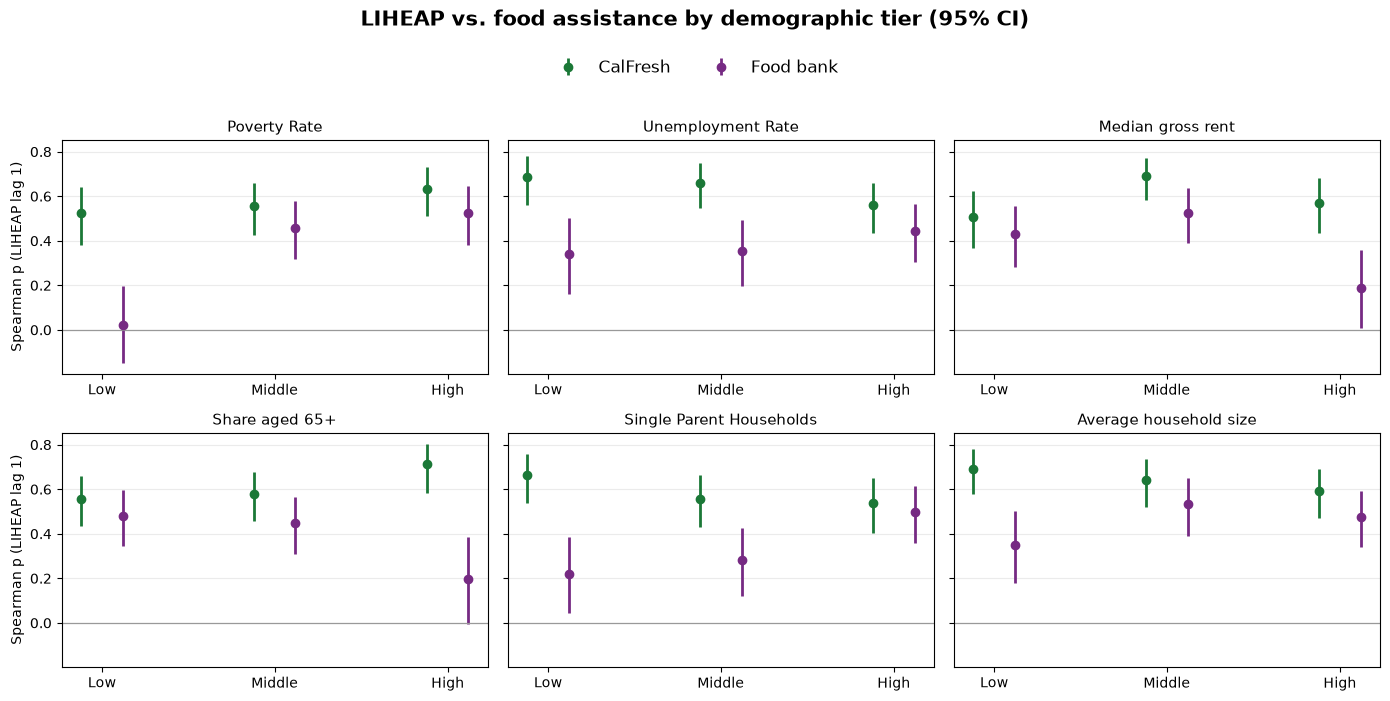

In [43]:
colors = {"CalFresh": "#1b7837", "Food bank": "#762a83"}
offset = {"CalFresh": -0.12, "Food bank": 0.12}

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, name in zip(axes.flat, DEMO_VARS.values()):
    g = seg_results[seg_results["Demographic"] == name]
    for label, gg in g.groupby("Outcome"):
        xs = [TIERS.index(t) + offset[label] for t in gg["Tier"]]
        ax.errorbar(xs, gg["Spearman_rho"],
                    yerr=[gg["Spearman_rho"] - gg["Spearman_CI_low"],
                          gg["Spearman_CI_high"] - gg["Spearman_rho"]],
                    fmt="o", color=colors[label], label=label, capsize=0, elinewidth=2)
        ax.set_xticks(range(3), TIERS)
        ax.set_title(name, fontsize=11)
        ax.axhline(0, color="#999", lw=0.8)
        ax.grid(axis="y", alpha=0.25)

axes[0, 0].set_ylabel("Spearman p (LIHEAP lag 1)")
axes[1, 0].set_ylabel("Spearman p (LIHEAP lag 1)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.945),  # ← legend height
           ncol=2, frameon=False, fontsize=12)
fig.suptitle("LIHEAP vs. food assistance by demographic tier (95% CI)",
             fontsize=15, fontweight="bold", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.91])
fig.savefig("Demographic_Tier_Correlations.png", dpi=200, bbox_inches="tight")
plt.show()

**Conclusions**

### Demographic segmentation: conclusions

**Method.** Zip codes were split into thirds (Low / Middle / High) on six ACS demographics, and the lag-1 Spearman correlation between LIHEAP enrollment and each food assistance outcome was recomputed within each tier. High and Low tiers were compared with Fisher z-tests, Bonferroni-adjusted for 12 comparisons (α = 0.05 / 12 = 0.0042).

**1. The food bank relationship depends on neighborhood poverty.**
This is the only difference that survives correction. In high-poverty zip codes, LIHEAP enrollment and food bank pounds are moderately correlated (ρ = 0.53, n = 133). In low-poverty zip codes there is essentially no relationship (ρ = 0.02, n = 128; p < 0.001 for the difference). The countywide food bank correlation (ρ ≈ 0.46) is therefore driven almost entirely by higher-poverty areas.

**2. Other food bank differences point the same way but are not significant after correction.**
- Single-parent households: High 0.50 vs. Low 0.22 (p = 0.012)
- Share aged 65+: High 0.20 vs. Low 0.48 (p = 0.016)
- Median gross rent: High 0.19 vs. Low 0.43 (p = 0.036)

Together these suggest the food bank link is strongest in lower-cost zip codes with younger, family households, and weakest in higher-rent, older zip codes. These demographics are correlated with poverty and with each other, so they likely reflect one underlying pattern rather than three separate findings. Treat them as suggestive.

**3. The CalFresh relationship is stable across every demographic tier.**
CalFresh correlations range from ρ = 0.51 to 0.71 in every tier. No High-vs-Low difference is close to significant: the smallest p-value is 0.046 (share aged 65+), and the largest gap is 0.16. LIHEAP enrollment tracks CalFresh dollars similarly regardless of a zip's poverty, rent, age profile or household makeup.

**4. Demographics explain little of the zip-to-zip variation in correlation strength.**
Each zip's own LIHEAP-vs-assistance correlation (from the zip ranking) was compared with its demographics across roughly 70 zip codes. Every relationship was weak (|ρ| ≤ 0.30):

- **Median gross rent** had the strongest association. Zips with higher rents tended to show weaker LIHEAP–assistance correlations (ρ = −0.30 with the average zip correlation; −0.28 for food bank; −0.17 for CalFresh). This matches the tier analysis, where food bank correlations were weaker in high-rent zip codes.
- **Poverty rate** was weakly positive (ρ = 0.21 average; 0.13 CalFresh; 0.12 food bank). The direction agrees with the tier result, but the effect is small at the individual-zip level.
- **Unemployment rate** was weakly negative for CalFresh only (ρ = −0.23).
- Household size, share aged 65+ and single-parent households showed no meaningful association (|ρ| ≤ 0.16).

None of these associations survives a Bonferroni adjustment for 18 tests. Each zip's correlation rests on only five or six months, so it is noisy, and that noise weakens any link to demographics. The zip-level results therefore support the tier findings in direction, but they show that demographics alone do not explain why a particular zip code ranks high or low. Other factors, such as where pantries are located, local outreach and small-sample variation, probably account for most of the differences between zip codes.

**Interpretation.** LIHEAP enrollment is a broadly reliable geographic marker for CalFresh need. For food bank distribution it is useful mainly in high-poverty zip codes. A plausible explanation is that food bank pounds are recorded where food is distributed, not where recipients live. Pantries cluster in higher-need areas, so in low-poverty zip codes the pounds reflect site locations more than local demand. This is an interpretation, not something the data can confirm.

**Caveats.**
- Each tier holds roughly 40 zip codes. These tests can only detect large differences, so "no difference" for CalFresh means no *large* difference.
- Zip codes contribute several months each, so observations are not independent and p-values are likely too small. Even so, the poverty result (p < 0.001) is far enough below the threshold to be robust to this.
- Tercile cut points are arbitrary; a different split could move borderline results.
- ACS figures are 5-year estimates and carry their own margins of error, especially for small zip codes.
- These are correlations between zip-level totals. They do not show that poverty *causes* the stronger food bank link, or that the same households use both programs.